# PRINT footprints and TF binding scores

[PRINT](https://www.nature.com/articles/s41586-024-08443-4) (Hu *et al.*,
*Nature* 2025) asks, at every base and every scale, whether Tn5 cut a
window **less than its sequence bias predicts** relative to the flanks —
the mark of something bound there. Small scales pick out transcription
factors, large ones nucleosomes. [scPrinter](https://github.com/buenrostrolab/scPrinter)
brought it to single-cell data and added a model that turns the footprint
around a site into a binding probability.

Epione runs the same computation in three calls:

```python
bias = epi.tl.tn5_bias(genome)                                   # PRINT CNN, on demand
fp   = epi.tl.multi_scale_footprint_region(adata, sites, groupby=..., bias=bias)
tfbs = epi.tl.tf_binding_score(adata, peaks, groupby=..., bias=bias)
```

**What is scPrinter's, and what is not.** The numbers are scPrinter's —
window geometry, learned null ("dispersion model"), smoothing, binding
model and published weights — and they match it **bit for bit** (last
section). The machinery is not: scPrinter keeps state in a `printer`
object over a backed AnnData plus a `_supp/` directory, passes models to
workers through `globals()`, and needs snapATAC2's genome-wide insertion
matrix and a precomputed bias file of **10.9 GB** for mm10. Here the
inputs are an insertion track read from the fragments file on demand, a
bias track computed on demand by a 0.1 MB CNN, and models loaded once.

| step | scPrinter | Epione |
|---|---|---|
| insertions | genome-wide `cells × bp` matrix (snapATAC2) | tabix read of the window asked for |
| Tn5 bias | 10.9 GB file, loaded whole per call | 0.1 MB CNN on the bases asked for |
| null | dispersion MLP (torch) | same MLP, same ops |
| results | h5ad side-cars keyed by region strings | dataclasses |

The sample is the one used in the scooby tutorial: GSE308623 `P2S1`,
mouse brain at P2, spatial ATAC, mm10, chr19.

## Part 1 · Setup

In [1]:
%matplotlib inline
import os, sys, pathlib, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import anndata as ad
import pysam
import warnings
warnings.filterwarnings('ignore', module='tqdm')


def _find_repo(start):  # works from the source tree or a pip install
    p = pathlib.Path(start).resolve()
    for cand in (p, *p.parents):
        if (cand / 'epione' / '__init__.py').exists():
            return cand
    return None


CODE = (pathlib.Path(os.environ['EPIONE_SRC']) if os.environ.get('EPIONE_SRC')
        else _find_repo(pathlib.Path.cwd()))
if CODE is not None:
    sys.path.insert(0, str(CODE))

import epione as epi

DATA  = pathlib.Path(os.environ.get('SCOOBY_TUTORIAL_DATA', (CODE or pathlib.Path.cwd()).parent))
FRAG  = DATA / 'scooby_bench' / 'P2S1.fragments.tsv.gz'
POS   = DATA / 'scooby_bench' / 'P2S1.positions.csv'
FASTA = DATA / 'genome' / 'mm10' / 'chr19.fa'
CHROM = 'chr19'
for p in (FRAG, POS, FASTA):
    if not p.exists():
        raise FileNotFoundError(f'{p} — see "Getting the inputs" in t_scooby_bridge')

# Same validated palette as the other tutorials.
C = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100']
INK, INK2, MUTED, GRID = '#0b0b0b', '#52514e', '#898781', '#e1e0d9'
plt.rcParams.update({
    'figure.facecolor': '#fcfcfb', 'axes.facecolor': '#fcfcfb', 'savefig.facecolor': '#fcfcfb',
    'axes.edgecolor': '#c3c2b7', 'axes.linewidth': 0.8, 'axes.labelcolor': INK2,
    'axes.titlesize': 11, 'axes.titleweight': 'bold', 'axes.titlecolor': INK,
    'axes.spines.top': False, 'axes.spines.right': False,
    'xtick.color': MUTED, 'ytick.color': MUTED, 'xtick.labelsize': 9, 'ytick.labelsize': 9,
    'grid.color': GRID, 'grid.linewidth': 0.6, 'legend.frameon': False,
    'legend.fontsize': 9, 'font.size': 10, 'lines.linewidth': 2.0, 'figure.dpi': 110,
})

## Part 2 · Cells, groups and peaks

Each 50 µm spot is one barcode. Groups here are four dorsal→ventral bands
of the section — crude, but deep: ~1,800 spots each, which is what
footprinting needs (a footprint is a *shortage* of cuts, so it takes many
cuts to see one).

In [2]:
pos = (pd.read_csv(POS, header=None, names=['bc', 'in_tissue', 'row', 'col', 'pr', 'pc'])
         .query('in_tissue == 1').reset_index(drop=True))
edges = np.quantile(pos['row'], [0, .25, .5, .75, 1])
band = np.clip(np.digitize(pos['row'], edges[1:-1]), 0, 3)

adata = ad.AnnData(
    X=np.zeros((len(pos), 1), dtype=np.float32),
    obs=pd.DataFrame({'band': [f'band {b + 1}' for b in band]}, index=pos['bc'] + '-1'),
)
adata.uns['files'] = {'fragments': str(FRAG)}
adata.uns['reference_sequences'] = {CHROM: pysam.FastaFile(str(FASTA)).get_reference_length(CHROM)}
adata.obs['band'].value_counts().sort_index()

band
band 1    1750
band 2    1762
band 3    1795
band 4    1824
Name: count, dtype: int64

In [3]:
%%time
# Stand-in peaks: the 200 densest 500-bp bins on chr19, widened to 1 kb.
keep, cnt = set(adata.obs_names), {}
for line in pysam.TabixFile(str(FRAG)).fetch(CHROM):
    f = line.split('\t', 4)
    if f[3] in keep:
        for p in (int(f[1]), int(f[2])):
            cnt[p // 500] = cnt.get(p // 500, 0) + 1
top = sorted(cnt.items(), key=lambda kv: -kv[1])[:200]
peaks = pd.DataFrame({'chrom': CHROM,
                      'start': [b * 500 - 250 for b, _ in top],
                      'end':   [b * 500 + 750 for b, _ in top],
                      'cuts':  [n for _, n in top]})
peaks.head()

CPU times: user 3.07 s, sys: 25.7 ms, total: 3.1 s
Wall time: 3.1 s


,chrom,start,end,cuts
0,chr19,61266250,61267250,2520
1,chr19,8251750,8252750,2096
2,chr19,59345250,59346250,1621
3,chr19,6979750,6980750,1353
4,chr19,61266750,61267750,1290


## Part 3 · Tn5 bias

`epi.tl.tn5_bias` returns an object with one method,
`track(chrom, start, end)`. The default is PRINT's CNN, run only on the
bases asked for. It reproduces scPrinter's genome-wide inference bit for
bit: CPU convolutions round differently for different input lengths, so
the region is run through the very chunks scPrinter's chromosome-wide
pass would have used.

The older hexamer table is still available. The two models were fitted
to **different cut conventions** — PRINT to cuts at a fragment's `start`
and `end`, the hexamer table to `start` and `end − 1` — and each bias
object carries its own, so footprinting reads insertions the way the
bias expects. A one-base mismatch here blurs every footprint.

In [4]:
%%time
bias = epi.tl.tn5_bias(FASTA)                     # PRINT CNN (downloads 0.1 MB once)
bias.track(CHROM, 1_000_000, 1_001_000)           # first call loads the model
t0 = time.time()
b = bias.track(CHROM, int(peaks.start[1]), int(peaks.end[1]))
print(f'1 kb of PRINT bias in {1e3 * (time.time() - t0):.0f} ms (model loaded);',
      f'cut convention {bias.shift}')

table = epi.tl.compute_tn5_bias_table(str(FRAG), str(FASTA), chroms=[CHROM])
kmer = epi.tl.tn5_bias(FASTA, method='kmer', table=table)
print(f'hexamer table: {table.size:,} 6-mers; cut convention {kmer.shift}')

1 kb of PRINT bias in 9 ms (model loaded); cut convention (0, 0)


  └─ Tn5 bias: scanned 3,030,303 fragments, 6,060,577 cuts; k=6, bias range [0.013, 10.965]
hexamer table: 4,096 6-mers; cut convention (0, -1)
CPU times: user 23.4 s, sys: 2.71 s, total: 26.1 s
Wall time: 25.7 s


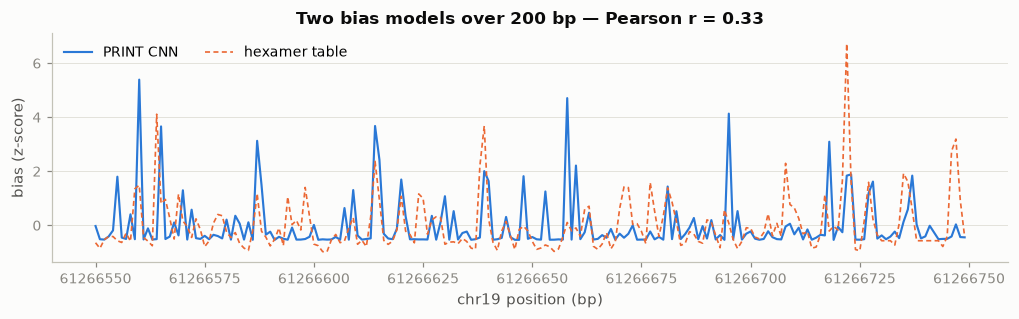

In [5]:
s0 = int(peaks.start[0]) + 300
x = np.arange(s0, s0 + 200)
pb, kb = bias.track(CHROM, s0, s0 + 200), kmer.track(CHROM, s0, s0 + 200)
z = lambda v: (v - v.mean()) / v.std()
r = np.corrcoef(pb, kb)[0, 1]

fig, ax = plt.subplots(figsize=(9.5, 3.0))
ax.plot(x, z(pb), color=C[0], lw=1.4, label='PRINT CNN')
ax.plot(x, z(kb), color=C[1], lw=1.1, ls=(0, (3, 2)), label='hexamer table')
ax.legend(loc='upper left', ncol=2)
ax.set_ylabel('bias (z-score)')
ax.set_xlabel(f'{CHROM} position (bp)')
ax.ticklabel_format(axis='x', style='plain', useOffset=False)
ax.grid(axis='y'); ax.set_axisbelow(True)
ax.set_title(f'Two bias models over 200 bp — Pearson r = {r:.2f}')
plt.tight_layout(); plt.show()

The two models correlate only weakly at base resolution. They are not
interchangeable: the CNN reads a 101-bp context and was trained on
deproteinised DNA, the hexamer table sees 6 bp and was estimated from
this sample's own (protein-bound) chromatin. The CNN is also the bias the
dispersion null and the binding model were fitted to, so pairing those
with the hexamer table would give uncalibrated scores — Epione refuses
that combination.

## Part 4 · Multi-scale footprint of one peak

`multi_scale_footprint_region` is the function Epione already had; it
now takes a `bias=` and picks PRINT's learned null automatically when
the bias is PRINT's. Above each heatmap is the evidence it rests on: cuts
observed in that band (filled) and the cuts the bias predicts (dashed,
rescaled to the same total). Footprints are where the filled track drops
below the dashed one.

In [6]:
%%time
dispersion = epi.tl.DispersionModel.load()        # 0.7 MB, once
summit = int(peaks.start[0]) + 500
fp = epi.tl.multi_scale_footprint_region(
    adata, [{'chrom': CHROM, 'center': summit}], groupby='band',
    bias=bias, dispersion=dispersion, flank=600)
print(fp.score.shape, '(groups, scales, positions);',
      'cuts per band:', dict(zip(fp.groups, fp.insertions.sum(1).astype(int))))

└─ multi_scale_footprint_region: 1 site(s) × 4 groups · print bias · dispersion null
(4, 50, 1201) (groups, scales, positions); cuts per band: {'band 1': np.int64(1036), 'band 2': np.int64(1049), 'band 3': np.int64(996), 'band 4': np.int64(1152)}
CPU times: user 326 ms, sys: 5.75 ms, total: 332 ms
Wall time: 151 ms


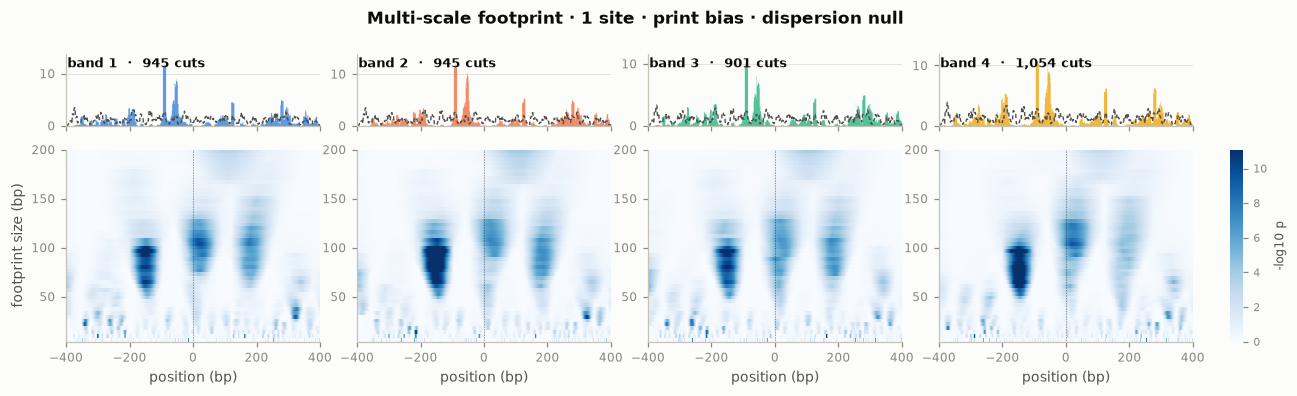

In [7]:
# Scores near the window edge have truncated flanks: read ±600, show ±400.
fig, axes = epi.pl.plot_multi_scale_footprint_region(fp, ncols=4, zoom=400, vpercentile=99.5)

## Part 5 · Why the learned null matters

PRINT's dispersion model is the piece that separates it from a textbook
test. A binomial null assumes each cut is an independent draw; real Tn5
data are overdispersed, so a binomial test calls far more "footprints"
than are there. Same insertions, same bias, two nulls:

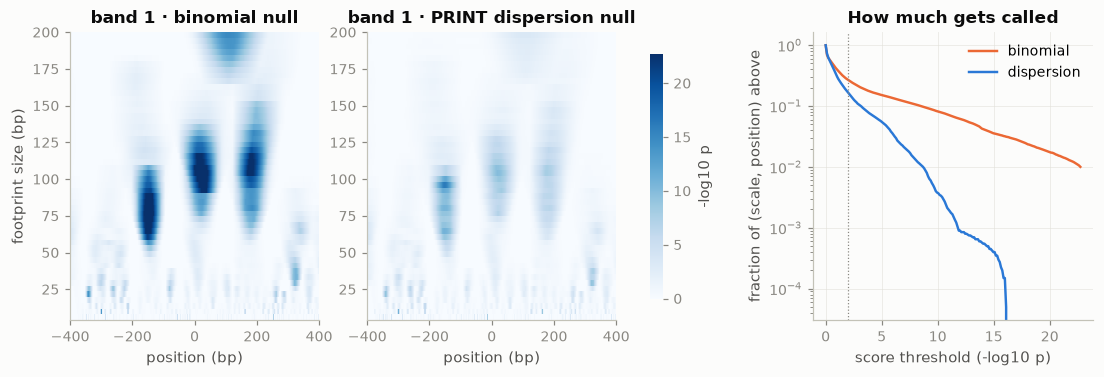

fraction with p < 0.01 — binomial: 0.268   dispersion: 0.167


In [8]:
fp_bin = epi.tl.multi_scale_footprint_region(
    adata, [{'chrom': CHROM, 'center': summit}], groupby='band',
    bias=bias, null='binomial', flank=600, verbose=False)

g = 0
inner = np.abs(fp.positions) <= 400           # drop the edge-truncated flanks
S_disp, S_bin = fp.score[g][:, inner], fp_bin.score[g][:, inner]
vmax = np.nanpercentile(np.stack([S_disp, S_bin]), 99.5)
fig, axes = plt.subplots(1, 3, figsize=(12, 3.4),
                         gridspec_kw={'width_ratios': [1, 1, 0.9]})
for ax, S, name in ((axes[0], S_bin, 'binomial null'), (axes[1], S_disp, 'PRINT dispersion null')):
    im = ax.imshow(S, aspect='auto', origin='lower', cmap='Blues',
                   vmin=0, vmax=vmax, interpolation='nearest',
                   extent=[-400, 400, 2 * fp.scales[0], 2 * fp.scales[-1]])
    ax.set_title(f'{fp.groups[g]} · {name}')
    ax.set_xlabel('position (bp)')
axes[0].set_ylabel('footprint size (bp)')
fig.colorbar(im, ax=axes[:2], shrink=0.85, label='-log10 p').outline.set_visible(False)

thr = np.linspace(0, vmax, 200)
for S, col, name in ((S_bin, C[1], 'binomial'), (S_disp, C[0], 'dispersion')):
    axes[2].plot(thr, [(S > t).mean() for t in thr], color=col, lw=1.6, label=name)
axes[2].axvline(2, color=MUTED, lw=0.8, ls=':')
axes[2].set_yscale('log'); axes[2].set_xlabel('score threshold (-log10 p)')
axes[2].set_ylabel('fraction of (scale, position) above'); axes[2].legend()
axes[2].grid(alpha=0.6); axes[2].set_axisbelow(True)
axes[2].set_title('How much gets called')
plt.show()
print('fraction with p < 0.01 — binomial: {:.3f}   dispersion: {:.3f}'.format(
      (S_bin > 2).mean(), (S_disp > 2).mean()))

## Part 6 · TF binding scores

`tf_binding_score` computes the footprint over each whole peak at the
six scales PRINT's binding model uses, then scores the 201-bp multi-scale
footprint around each site. Without motifs, every peak is tiled every
10 bp — a scan for any bound factor. Each score is a probability.

In [9]:
%%time
tfbs = epi.tl.tf_binding_score(adata, peaks, groupby='band', bias=bias, dispersion=dispersion)
tfbs.to_frame().head()

└─ tf_binding_score: 16,000 sites in 200 region(s) x 4 groups
CPU times: user 10.4 s, sys: 87.8 ms, total: 10.5 s
Wall time: 3.3 s


,chrom,center,strand,region,position,group,score
0,chr19,61266355,+,chr19:61266250-61267250,105,band 1,0.025844
1,chr19,61266355,+,chr19:61266250-61267250,105,band 2,0.010080
2,chr19,61266355,+,chr19:61266250-61267250,105,band 3,0.002697
3,chr19,61266355,+,chr19:61266250-61267250,105,band 4,0.005405
4,chr19,61266365,+,chr19:61266250-61267250,115,band 1,0.054385


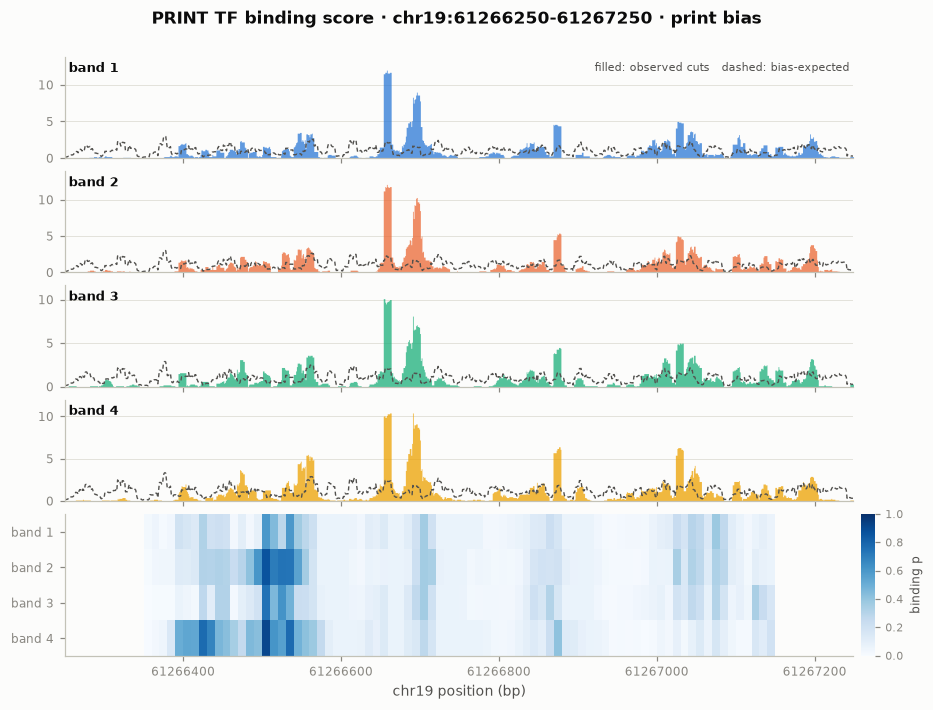

In [10]:
fig, axes = epi.pl.plot_tf_binding_score(tfbs, region=f'{CHROM}:{peaks.start[0]}-{peaks.end[0]}')

Across all 200 peaks, how do two bands compare site by site? Read the
highlighted sites as **candidates**, not differential binding: at ~950
cuts per band per peak, a 0.3 difference in probability is well within
what sampling noise alone produces. Calling a site differentially bound
needs replicate sections or a permutation null over spots; the cut-track
view above is how to inspect any one of them.

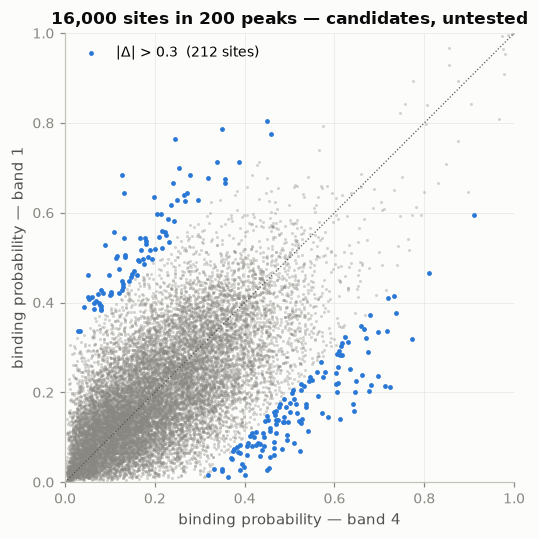

In [11]:
i1, i4 = tfbs.groups.index('band 1'), tfbs.groups.index('band 4')
d = tfbs.score[i1] - tfbs.score[i4]
fig, ax = plt.subplots(figsize=(5.2, 5))
ax.scatter(tfbs.score[i4], tfbs.score[i1], s=4, color=MUTED, alpha=0.35, lw=0)
hi = np.abs(d) > 0.3
ax.scatter(tfbs.score[i4][hi], tfbs.score[i1][hi], s=10, color=C[0], lw=0,
           label=f'|Δ| > 0.3  ({hi.sum()} sites)')
ax.plot([0, 1], [0, 1], color=INK2, lw=0.8, ls=':')
ax.set_xlabel('binding probability — band 4'); ax.set_ylabel('binding probability — band 1')
ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.set_aspect('equal'); ax.legend(loc='upper left')
ax.grid(alpha=0.6); ax.set_axisbelow(True)
ax.set_title(f'{tfbs.score.shape[1]:,} sites in 200 peaks — candidates, untested')
plt.tight_layout(); plt.show()

## Part 7 · Exactness against scPrinter

The claim that these are scPrinter's numbers is checked, not assumed:
here scPrinter's own `multiscale_footprints` and
`getRegionBindingScore` — lifted verbatim from its source — are run on
the **same real insertion and bias tracks** as above and compared with
`np.array_equal`. The test suite (`tests/test_print.py`) additionally
checks the CNN bias against scPrinter's chromosome-wide inference and
every one of the 99 scales' p-values.

Set `SCPRINTER_SRC` to the `scprinter/` directory of a clone of
scPrinter to run this section.

In [12]:
SRC = os.environ.get('SCPRINTER_SRC')
if not SRC:
    print('SCPRINTER_SRC not set — skipping.')
else:
    import ast, importlib.util, torch
    parts = ['import os, warnings, time', 'import numpy as np, torch, h5py, scipy, scipy.stats',
             'import torch.nn.functional as F', 'from scipy.ndimage import maximum_filter']
    want = {'utils.py': {'rz_conv', 'load_entire_hdf5', 'loadDispModel', 'loadBindingScoreModel_pt',
                         'strided_lastaxis'},
            'footprint.py': {'predictDispersion_jit', 'footprintWindowSum', 'footprintScoring',
                             'regionFootprintScore', 'multiscale_footprints'},
            'TFBS.py': {'getRegionBindingScore'}}
    for fname, names in want.items():
        text = (pathlib.Path(SRC) / fname).read_text(); lines = text.splitlines(keepends=True)
        for node in ast.parse(text).body:
            if isinstance(node, ast.FunctionDef) and node.name in names:
                first = (node.decorator_list[0].lineno if node.decorator_list else node.lineno) - 1
                parts.append(''.join(lines[first:node.end_lineno]))
    ref_path = pathlib.Path(os.environ.get('TMPDIR', '/tmp')) / 'scprinter_ref_nb.py'
    ref_path.write_text('\n\n'.join(parts))
    spec = importlib.util.spec_from_file_location('scprinter_ref_nb', ref_path)
    ref = importlib.util.module_from_spec(spec); sys.modules['scprinter_ref_nb'] = ref
    spec.loader.exec_module(ref)

    ref_disp = ref.loadDispModel(dispersion.path)
    want_fp = ref.multiscale_footprints(fp.insertions.astype(float), fp.bias.astype(float),
                                        ref_disp, modes=fp.scales, smoothRadius=None)
    print('multi-scale footprint, real data:', fp.score.shape,
          '→ identical:', np.array_equal(fp.score, want_fp.astype(np.float32)))

    rid = f'{CHROM}:{peaks.start[0]}-{peaks.end[0]}'
    tr = tfbs.tracks[rid]
    net = ref.loadBindingScoreModel_pt(epi.tl.fetch_print_model('tf_binding'))
    # scPrinter's own tiling sets Score = 1 on every tile.
    tiles = epi.tl._print._tile_sites(tr['start'], tr['end'], 10).assign(Score=1)

    class _Region:
        df = pd.DataFrame({'Start': [tr['start']], 'End': [tr['end']]})

    with torch.no_grad():
        want_tf = ref.getRegionBindingScore('r', tr['insertions'], tr['bias'], _Region(),
                                            [ref_disp[str(s)] for s in net['scales']], net,
                                            sites=tiles)
    got_tf = tfbs.score[:, (tfbs.sites['region'] == rid).to_numpy()]
    print('TF binding scores, real data:', got_tf.shape,
          '→ identical:', np.array_equal(got_tf, want_tf['BindingScore']))

multi-scale footprint, real data: (4, 50, 1201) → identical: True
TF binding scores, real data: (4, 80) → identical: True


## Summary

| | |
|---|---|
| Inputs | fragments file + FASTA; no snapATAC2, no genome-wide bias file |
| Tn5 bias | `epi.tl.tn5_bias(genome)` — PRINT CNN on demand, bit-identical to scPrinter |
| Footprints | `epi.tl.multi_scale_footprint_region(..., bias=bias)` — learned null by default with PRINT bias |
| Binding | `epi.tl.tf_binding_score(...)` → `TFBindingResult` (`.score`, `.sites`, `.to_frame()`) |
| Plots | `epi.pl.plot_multi_scale_footprint_region`, `epi.pl.plot_tf_binding_score` — evidence above score |
| Exactness | `np.array_equal` against scPrinter's own functions on real data |

Not included yet: **seq2PRINT**, scPrinter's sequence model that learns to
predict these footprints from DNA. It is a training workflow (GPU, five
folds, LoRA per cell state) rather than an analysis step, and will come
as `epione.models.seq2print`, next to the scooby bridge.